In [1]:
## import basic library

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
import numpy as np
import matplotlib.pyplot as plt



In [2]:
## load annotated csv dataset

df20 = pd.read_csv("../data/csv/ant_df20_.csv")
df30 = pd.read_csv("../data/csv/ant_df30_.csv")
df40 = pd.read_csv("../data/csv/ant_df40_.csv")

In [3]:
## load points and labels from DBscan 

points_20 = np.load(
    "../data/npy_files/20dbscan_points_min100.npy"
)

labels_20= np.load(
    "../data/npy_files/20dbscan_labels_min100.npy"
)

points_30 = np.load(
    "../data/npy_files/30dbscan_points_min100.npy"
)

labels_30= np.load(
    "../data/npy_files/30dbscan_labels_min100.npy"
)

points_40 = np.load(
    "../data/npy_files/40dbscan_points_min100.npy"
)

labels_40= np.load(
    "../data/npy_files/40dbscan_labels_min100.npy"
)

In [4]:
# add filename column

df20['file_name'] = '20'
df30['file_name'] = '30'
df40['file_name'] = '40'


In [5]:
cols = list(df20.columns)

cols.insert(13, cols.pop(cols.index("file_name")))

df20 = df20[cols]

In [6]:
cols = list(df30.columns)

cols.insert(13, cols.pop(cols.index("file_name")))

df30 = df30[cols]

In [7]:
cols = list(df40.columns)

cols.insert(13, cols.pop(cols.index("file_name")))

df40 = df40[cols]

In [8]:
## check shape of each dataset

print(df20.shape)
print(df30.shape)
print(df40.shape)

(32, 15)
(42, 15)
(12, 15)


In [9]:
df20.head()

,cluster_id,points,width,length,height,volume,density,center_x,center_y,center_z,geometry,min_distance_pipeline,pipeline_risk,file_name,labels
0,9,774,4.695,4.0950,1.883,36.202605,21.379677,371550.502168,5.643516e+06,161.519889,"POLYGON ((371552.369 5643514.087, 371549.32899...",0.000000,High,20,building
1,10,2388,25.524,14.9560,3.664,1398.684163,1.707319,371718.147397,5.643689e+06,162.097273,"POLYGON ((371705.626 5643681.914, 371704.104 5...",0.833678,High,20,tree
2,11,11719,30.277,8.0265,8.369,2033.820492,5.762062,371477.457783,5.643368e+06,163.353003,"POLYGON ((371467.132 5643361.796, 371465.198 5...",0.000000,High,20,building
3,17,385,2.837,4.2710,1.344,16.285015,23.641365,371451.341794,5.643275e+06,155.999174,"POLYGON ((371450.769 5643273.005, 371450.6535 ...",0.000000,High,20,tree
4,25,14727,35.485,75.5930,7.974,21389.597982,0.688512,371640.936723,5.643576e+06,158.853393,"POLYGON ((371626.967 5643540.752, 371623.169 5...",0.000000,High,20,wall


In [10]:
df30.head()

,cluster_id,points,width,length,height,volume,density,center_x,center_y,center_z,geometry,min_distance_pipeline,pipeline_risk,file_name,labels
0,1,18187,59.416,9.146,8.356,4540.806958,4.005235,371478.147537,5.643375e+06,163.908360,"POLYGON ((371477.24 5643371.578, 371474.14 564...",0.000000,High,30,wall
1,2,11910,24.934,6.269,11.984,1873.233972,6.357988,371479.887420,5.643368e+06,163.387076,"POLYGON ((371468.515 5643363.587, 371468.349 5...",0.000000,High,30,tree
2,4,12701,20.937,25.901,6.361,3449.501837,3.681981,371761.462822,5.643650e+06,161.224565,"POLYGON ((371768.493 5643638.5770000005, 37176...",0.000000,High,30,building
3,5,15391,21.452,53.302,6.892,7880.550602,1.953036,371526.035806,5.643454e+06,160.890125,"POLYGON ((371518.874 5643427.835, 371518.034 5...",0.000000,High,30,wall
4,6,1969,3.992,4.637,7.917,146.550827,13.435612,371763.420348,5.643563e+06,157.439956,"POLYGON ((371763.721 5643561.2385, 371763.219 ...",1.215249,High,30,building


In [11]:
df40.head()

,cluster_id,points,width,length,height,volume,density,center_x,center_y,center_z,geometry,min_distance_pipeline,pipeline_risk,file_name,labels
0,1,21107,14.669000,23.5080,13.578000,4682.221932,4.507903,371781.446568,5.643620e+06,160.388738,POLYGON ((371783.19200000004 5643608.958000001...,0.000000,High,40,building
1,2,7314,10.838000,13.8157,6.410974,959.944302,7.619192,371767.708256,5.643642e+06,161.070582,"POLYGON ((371768.3596 5643638.398799999, 37176...",2.159373,Medium,40,building
2,3,536,2.843182,3.4850,1.254500,12.430199,43.120790,371780.731601,5.643584e+06,154.361737,"POLYGON ((371778.89400000003 5643582.527, 3717...",0.187952,High,40,vehicle
3,4,1282,5.863000,3.1220,5.214000,95.438547,13.432728,371782.842363,5.643606e+06,159.444175,"POLYGON ((371779.868 5643604.416, 371779.835 5...",3.437070,Medium,40,building
4,5,6987,19.029000,25.1330,5.400000,2582.581628,2.705432,371786.937222,5.643596e+06,156.223564,"POLYGON ((371776.434 5643582.8100000005, 37177...",2.015103,Medium,40,wall


In [12]:
# merge all three annotated dataset

objects = pd.concat(
    [df20, df30, df40],
    ignore_index=True
)

print(objects.shape)

(86, 15)


In [176]:
# save as one csv file

objects.to_csv(
    "../data/csv/all_object_features.csv",
    index=False
)

In [177]:
objects.info()

<class 'pandas.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cluster_id             86 non-null     int64  
 1   points                 86 non-null     int64  
 2   width                  86 non-null     float64
 3   length                 86 non-null     float64
 4   height                 86 non-null     float64
 5   volume                 86 non-null     float64
 6   density                86 non-null     float64
 7   center_x               86 non-null     float64
 8   center_y               86 non-null     float64
 9   center_z               86 non-null     float64
 10  geometry               86 non-null     str    
 11  min_distance_pipeline  86 non-null     float64
 12  pipeline_risk          86 non-null     str    
 13  file_name              86 non-null     str    
 14  labels                 86 non-null     str    
dtypes: float64(9), int6

In [13]:
# Load the dataset  (from here we start machine learning pipeline )

csv_path = '../data/csv/all_object_features.csv'

df = pd.read_csv(csv_path)

print(f"Dataset loaded successfully.")
print(f"Number of samples : {len(df)}")
print(f"Number of columns : {len(df.columns)}")

Dataset loaded successfully.
Number of samples : 86
Number of columns : 15


In [14]:
# Inspect the labels

print(df["labels"].value_counts())

labels
vehicle     37
wall        21
building    17
tree         8
pole         3
Name: count, dtype: int64


In [15]:
#   Create a unique index using file name and cluster ID.

df["cluster_index"] = (
        df["file_name"].astype(str)
        + "_"
        + df["cluster_id"].astype(str)
    )
df = df.set_index("cluster_index")


In [16]:
# Keep only what matters for classification 

columns_to_keep = [
    'points',
    'width',
    'length',
    'height',
    'volume',
    'density',
    'labels',
]

df_clean = df[columns_to_keep]

print(df_clean.info())

<class 'pandas.DataFrame'>
Index: 86 entries, 20_9 to 40_15
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   points   86 non-null     int64  
 1   width    86 non-null     float64
 2   length   86 non-null     float64
 3   height   86 non-null     float64
 4   volume   86 non-null     float64
 5   density  86 non-null     float64
 6   labels   86 non-null     str    
dtypes: float64(5), int64(1), str(1)
memory usage: 5.4+ KB
None


In [17]:
#  add the aspect ratio features 

df_clean['elongation'] = df_clean['length'] / df_clean['width']
df_clean['flatness'] = df_clean['height'] / df_clean['width']

print(df_clean.head())

               points   width   length  height        volume    density  \
cluster_index                                                             
20_9              774   4.695   4.0950   1.883     36.202605  21.379677   
20_10            2388  25.524  14.9560   3.664   1398.684163   1.707319   
20_11           11719  30.277   8.0265   8.369   2033.820492   5.762062   
20_17             385   2.837   4.2710   1.344     16.285015  23.641365   
20_25           14727  35.485  75.5930   7.974  21389.597982   0.688512   

                 labels  elongation  flatness  
cluster_index                                  
20_9           building    0.872204  0.401065  
20_10              tree    0.585958  0.143551  
20_11          building    0.265102  0.276414  
20_17              tree    1.505464  0.473740  
20_25              wall    2.130280  0.224715  


In [18]:
# Convert labels to one hot encoding 

label_map = {
    'building': 0,
    'pole': 1,
    'tree': 2,
    'wall': 3,
    'vehicle': 4,
}

df_clean['labels'] = df_clean['labels'].map(label_map)

print(df_clean['labels'].head(10))

cluster_index
20_9     0
20_10    2
20_11    0
20_17    2
20_25    3
20_27    3
20_28    4
20_29    3
20_35    3
20_36    3
Name: labels, dtype: int64


In [19]:
df_clean.head()

,points,width,length,height,volume,density,labels,elongation,flatness
cluster_index,,,,,,,,,
20_9,774,4.695,4.0950,1.883,36.202605,21.379677,0,0.872204,0.401065
20_10,2388,25.524,14.9560,3.664,1398.684163,1.707319,2,0.585958,0.143551
20_11,11719,30.277,8.0265,8.369,2033.820492,5.762062,0,0.265102,0.276414
20_17,385,2.837,4.2710,1.344,16.285015,23.641365,2,1.505464,0.473740
20_25,14727,35.485,75.5930,7.974,21389.597982,0.688512,3,2.130280,0.224715


In [20]:
# Reorder columns exactly how you want them

column_order = [
    'points',
    'width',
    'length',
    'height',
    'volume',
    'density',
    'elongation',
    'flatness',
     'labels',
   
]

df_clean = df_clean[column_order]

print(df_clean.columns.tolist())

['points', 'width', 'length', 'height', 'volume', 'density', 'elongation', 'flatness', 'labels']


In [21]:
df_clean.head()

,points,width,length,height,volume,density,elongation,flatness,labels
cluster_index,,,,,,,,,
20_9,774,4.695,4.0950,1.883,36.202605,21.379677,0.872204,0.401065,0
20_10,2388,25.524,14.9560,3.664,1398.684163,1.707319,0.585958,0.143551,2
20_11,11719,30.277,8.0265,8.369,2033.820492,5.762062,0.265102,0.276414,0
20_17,385,2.837,4.2710,1.344,16.285015,23.641365,1.505464,0.473740,2
20_25,14727,35.485,75.5930,7.974,21389.597982,0.688512,2.130280,0.224715,3


In [22]:
# Build X and y

X = df_clean.drop(columns=['labels'])
y = df_clean['labels']

In [23]:
print(X.shape)
print(y.shape)

(86, 8)
(86,)


In [24]:
# Split the dataset



X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )



In [25]:
# Split the dataset

print('X_train shape: ', X_train.shape)
print('y_train shape: ',y_train.shape)
print('X_test shape: ',X_test.shape)
print('y_test shape: ',y_test.shape)

X_train shape:  (68, 8)
y_train shape:  (68,)
X_test shape:  (18, 8)
y_test shape:  (18,)


In [26]:
# Train Random Forest

rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

rf_model = rf.fit(X_train,y_train)




In [27]:
# Train XB Boost

xgb = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        eval_metric="logloss"
    )

xgb_model = xgb.fit(
        X_train,
        y_train
    )

In [28]:
# Predict Random Forest

y_pred_rf = rf_model.predict(
    X_test
)

In [29]:
# Predict XB Boost

y_pred_xgb = xgb_model.predict(
    X_test
)

In [30]:
# fuction for feature_importance

def feature_importance(
    model,
    features,
    model_name
):
    print("======================")
    print('feature_importance: ',model_name)
    print("======================")

    importance = pd.DataFrame(
        {
            "Feature": features,
            "Importance": model.feature_importances_
        }
    )

    importance = importance.sort_values(
        by="Importance",
        ascending=False
    )

    return importance

In [31]:
FEATURE_COLUMNS = ['points', 'width', 'length', 'height', 'volume', 'density', 'elongation', 'flatness']

In [32]:

# funtion for evaluate_classifier

def evaluate_classifier(
    y_test,
    y_pred,
    model_name
):
    

    print("======================")
    print(model_name)
    print("======================")

    print(
        classification_report(
            y_test,
            y_pred
        )
    )

In [33]:
# Random Forest Evaluation

evaluate_classifier(
    y_test,
    y_pred_rf,
    "Random Forest"
)

# XG Boost Evaluation

evaluate_classifier(
    y_test,
    y_pred_xgb,
    "XGBoost"
)

Random Forest
              precision    recall  f1-score   support

           0       0.20      0.33      0.25         3
           1       0.00      0.00      0.00         1
           2       1.00      0.50      0.67         2
           3       0.67      0.50      0.57         4
           4       0.78      0.88      0.82         8

    accuracy                           0.61        18
   macro avg       0.53      0.44      0.46        18
weighted avg       0.64      0.61      0.61        18

XGBoost
              precision    recall  f1-score   support

           0       0.17      0.33      0.22         3
           1       0.00      0.00      0.00         1
           2       1.00      0.50      0.67         2
           3       0.50      0.50      0.50         4
           4       1.00      0.88      0.93         8

    accuracy                           0.61        18
   macro avg       0.53      0.44      0.46        18
weighted avg       0.69      0.61      0.64        18



lidar_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
lidar_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
lidar_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
lidar_env/lib/python3.11/site-packages/s

In [34]:
feature_importance(
    rf_model,
    FEATURE_COLUMNS,
    "Random Forest"
    
)

feature_importance:  Random Forest


,Feature,Importance
3,height,0.155568
4,volume,0.141036
1,width,0.134325
0,points,0.131918
5,density,0.125543
7,flatness,0.115621
2,length,0.107796
6,elongation,0.088194


In [35]:
feature_importance(
    xgb_model,
    FEATURE_COLUMNS,
    "XGBoost"
    
)

feature_importance:  XGBoost


,Feature,Importance
4,volume,0.323734
7,flatness,0.142242
3,height,0.118342
1,width,0.099163
6,elongation,0.096952
5,density,0.081012
2,length,0.076490
0,points,0.062065


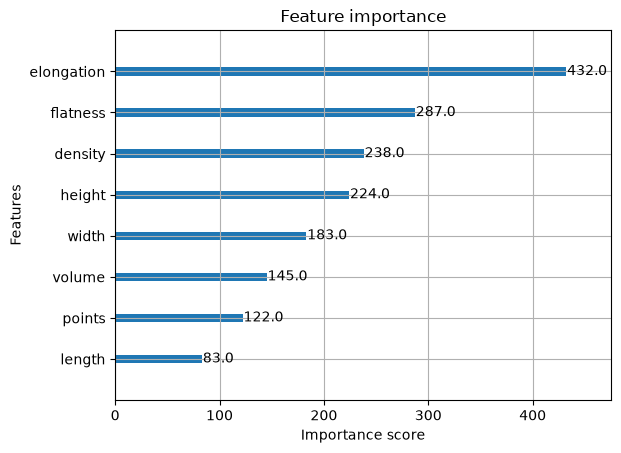

In [36]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(xgb_model)
plt.show()

In [37]:
reverse_label_map = {
    0: 'building',
    1: 'pole',
    2: 'tree',
    3: 'wall',
    4: 'vehicle'
}

In [38]:


def visualize_cluster(points, labels, cluster_id):
    mask = labels == cluster_id
    cluster = points[mask]

    print("Cluster ID:", cluster_id)
    print("Number of points:", len(cluster))

    if len(cluster) == 0:
        print("No points in this cluster, skipping.")
        return

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    # Top view
    ax[0].scatter(cluster[:, 0], cluster[:, 1], s=1)
    ax[0].set_title("Top view XY")
    ax[0].axis("equal")

    # Side view
    ax[1].scatter(cluster[:, 0], cluster[:, 2], s=1)
    ax[1].set_title("Side view XZ")
    ax[1].axis("equal")

    # Front view
    ax[2].scatter(cluster[:, 1], cluster[:, 2], s=1)
    ax[2].set_title("Front view YZ")
    ax[2].axis("equal")

    fig.suptitle(f"Cluster {cluster_id} — {len(cluster)} points")
    plt.show()

In [39]:
# function for Display actual and predicted classes for each sample and classify movable/non-movable based on class.

def show_predictions(
    cluster_ids,
    y_test,
    y_pred,
    reverse_label_map,
    point_clouds
):
    """
    Display predictions and visualize the corresponding LiDAR cluster.

    """

    for i in range(len(y_test)):

        # Decode labels
        actual = reverse_label_map[y_test.iloc[i]]
        predicted = reverse_label_map[y_pred[i]]

        # Parse cluster index
        file_name, cluster_id = cluster_ids[i].split("_")
        cluster_id = int(cluster_id)

        print("=" * 60)
        print(f"File: {file_name}")
        print(f"Cluster ID: {cluster_id}")
        print(f"Actual    : {actual}")
        print(f"Predicted : {predicted}")

        if predicted == "vehicle":
            print("Mobility  : Movable")
        else:
            print("Mobility  : Non-movable")

        # Visualize the correct cluster
        if file_name in point_clouds:

            points, labels = point_clouds[file_name]

            visualize_cluster(
                points,
                labels,
                cluster_id
            )

        else:
            print(f"No point cloud found for file '{file_name}'")

        print("=" * 60)

In [40]:
point_clouds = {
    "20": (points_20, labels_20),
    "30": (points_30, labels_30),
    "40": (points_40, labels_40),
}

File: 30
Cluster ID: 63
Actual    : tree
Predicted : tree
Mobility  : Non-movable
Cluster ID: 63
Number of points: 3091


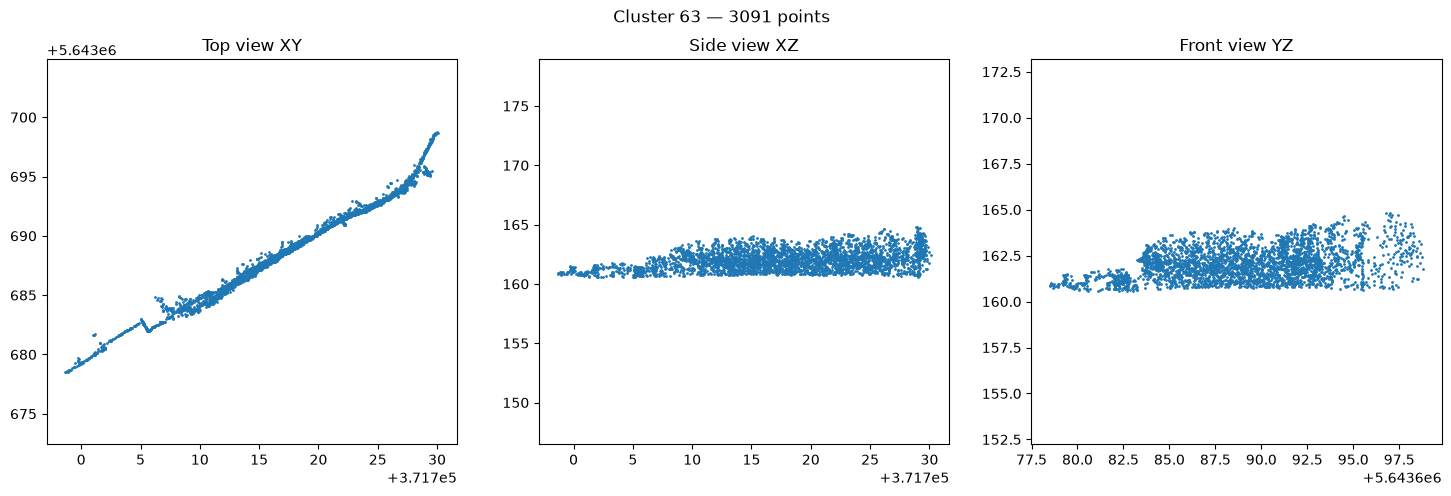

File: 20
Cluster ID: 56
Actual    : building
Predicted : wall
Mobility  : Non-movable
Cluster ID: 56
Number of points: 1411


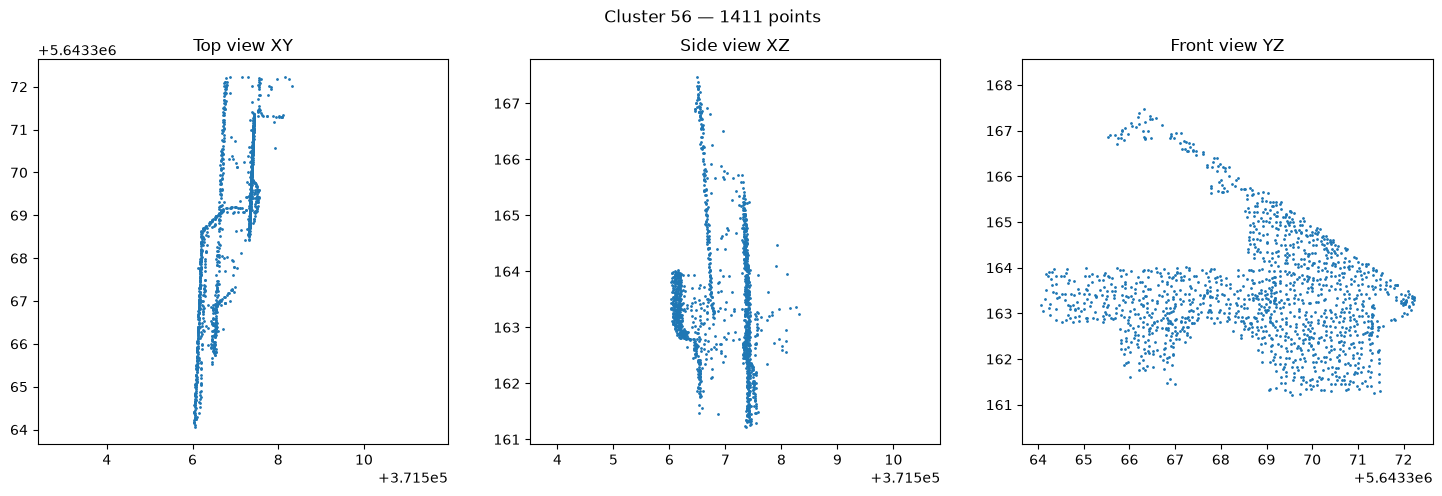

File: 30
Cluster ID: 108
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 108
Number of points: 354


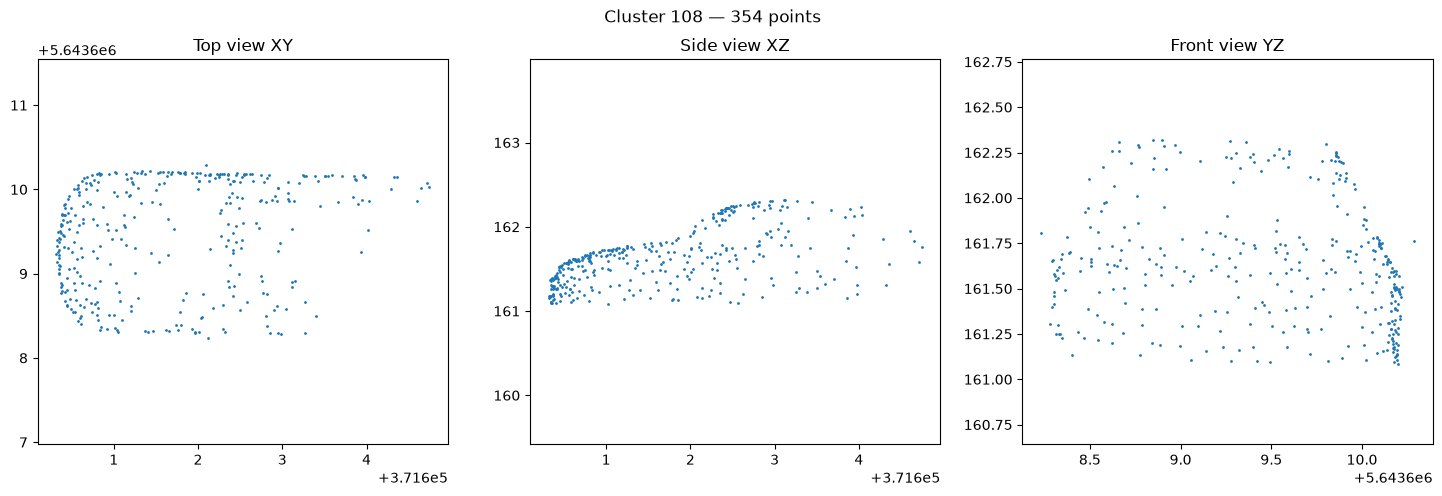

File: 30
Cluster ID: 61
Actual    : vehicle
Predicted : building
Mobility  : Non-movable
Cluster ID: 61
Number of points: 780


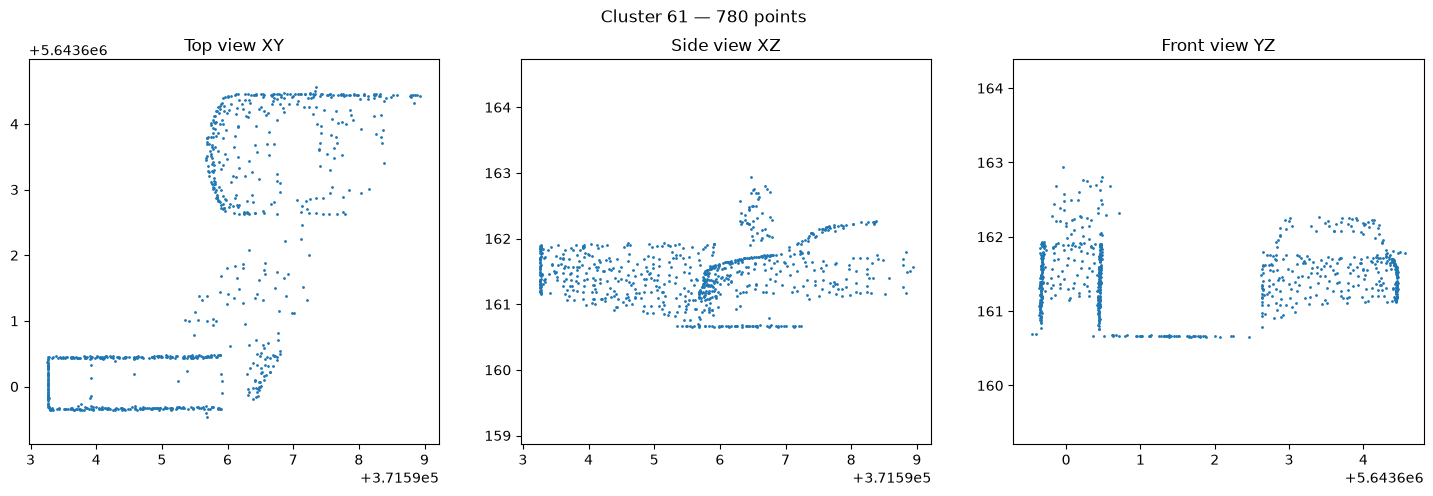

File: 30
Cluster ID: 30
Actual    : wall
Predicted : building
Mobility  : Non-movable
Cluster ID: 30
Number of points: 6072


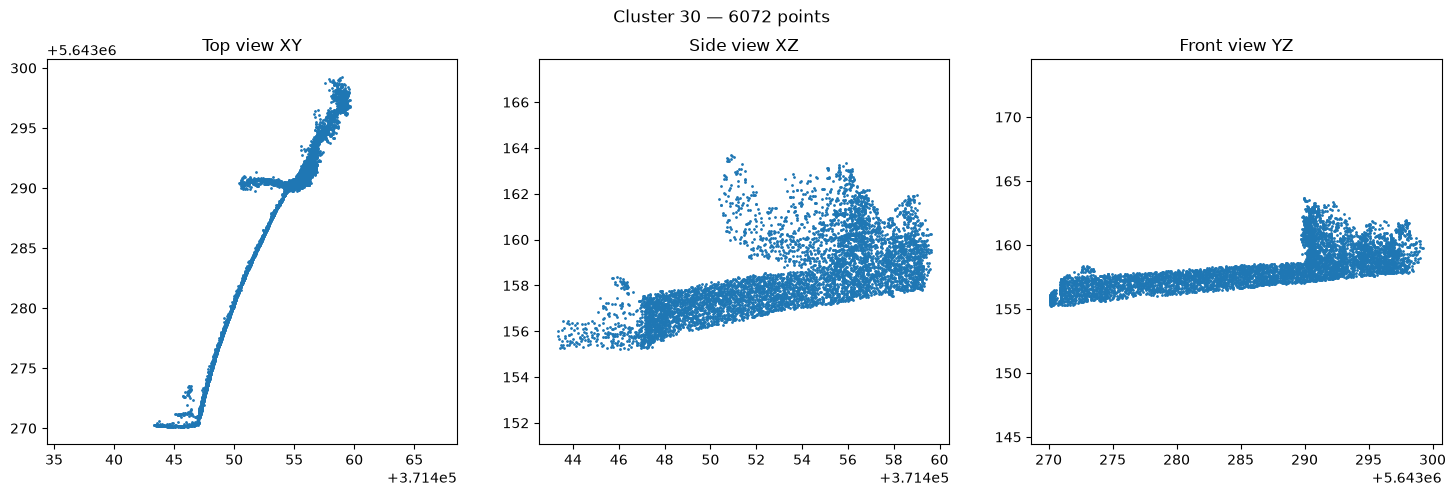

File: 30
Cluster ID: 22
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 22
Number of points: 380


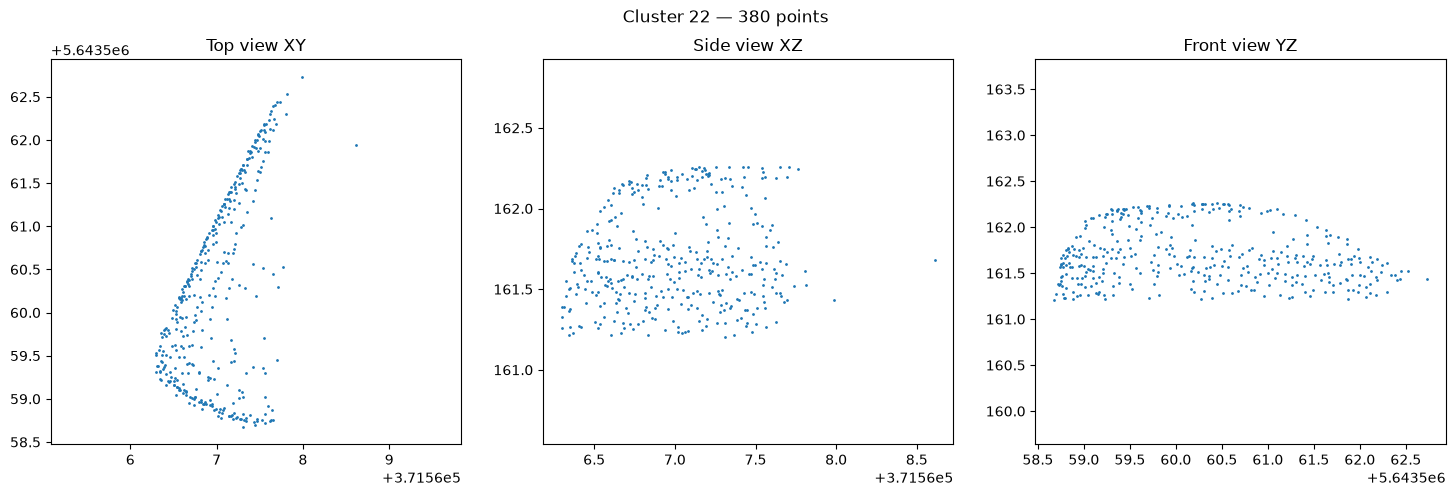

File: 20
Cluster ID: 74
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 74
Number of points: 244


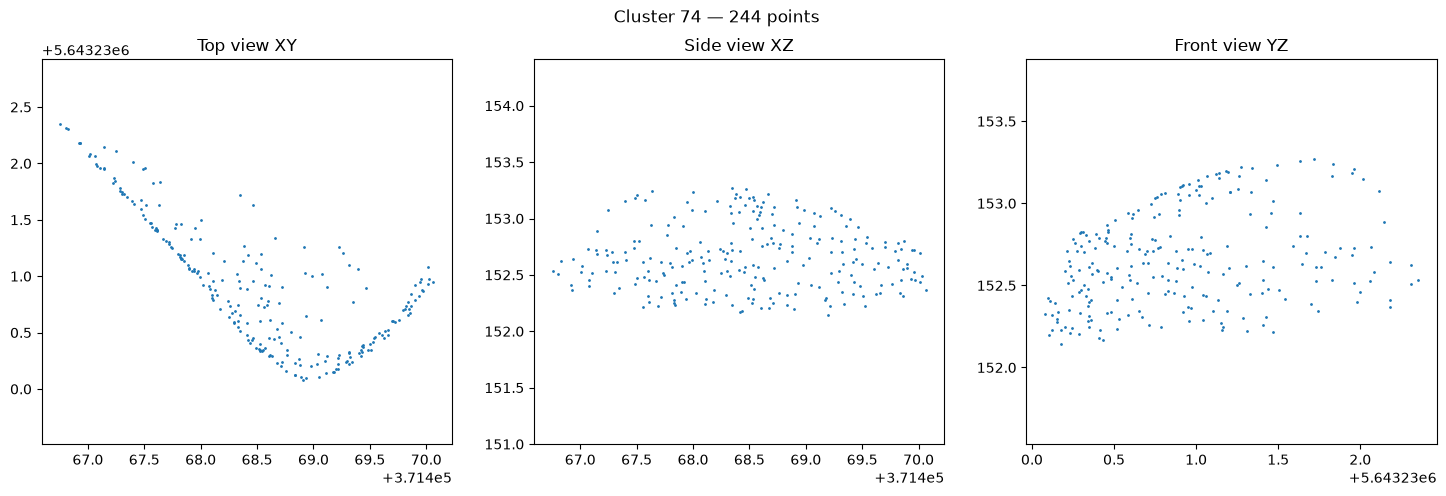

File: 40
Cluster ID: 5
Actual    : wall
Predicted : wall
Mobility  : Non-movable
Cluster ID: 5
Number of points: 6987


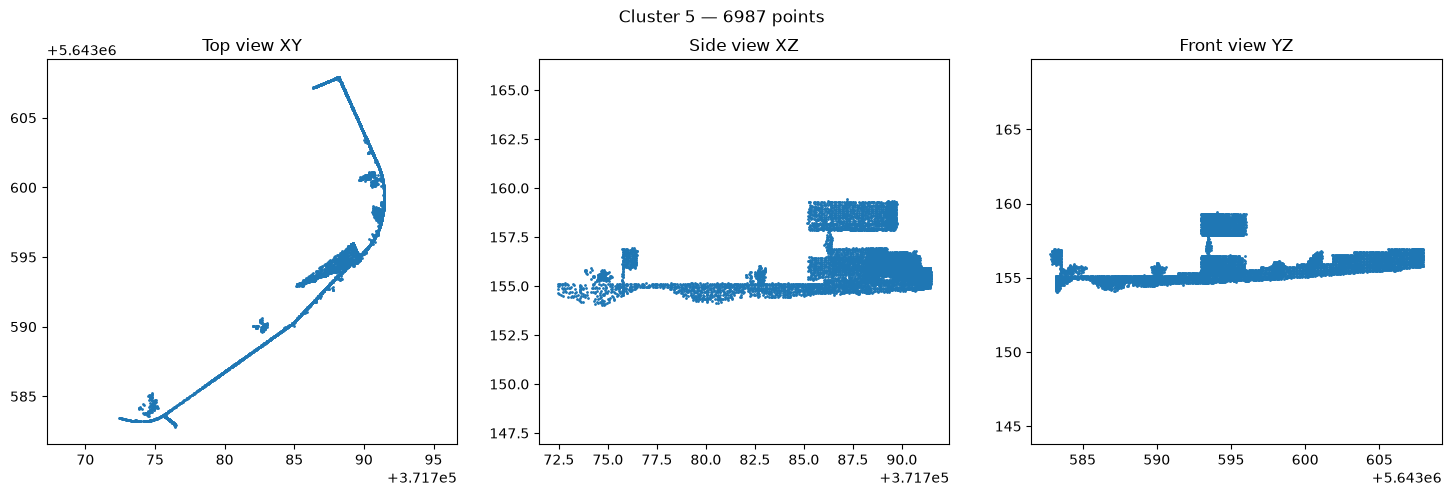

File: 30
Cluster ID: 115
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 115
Number of points: 317


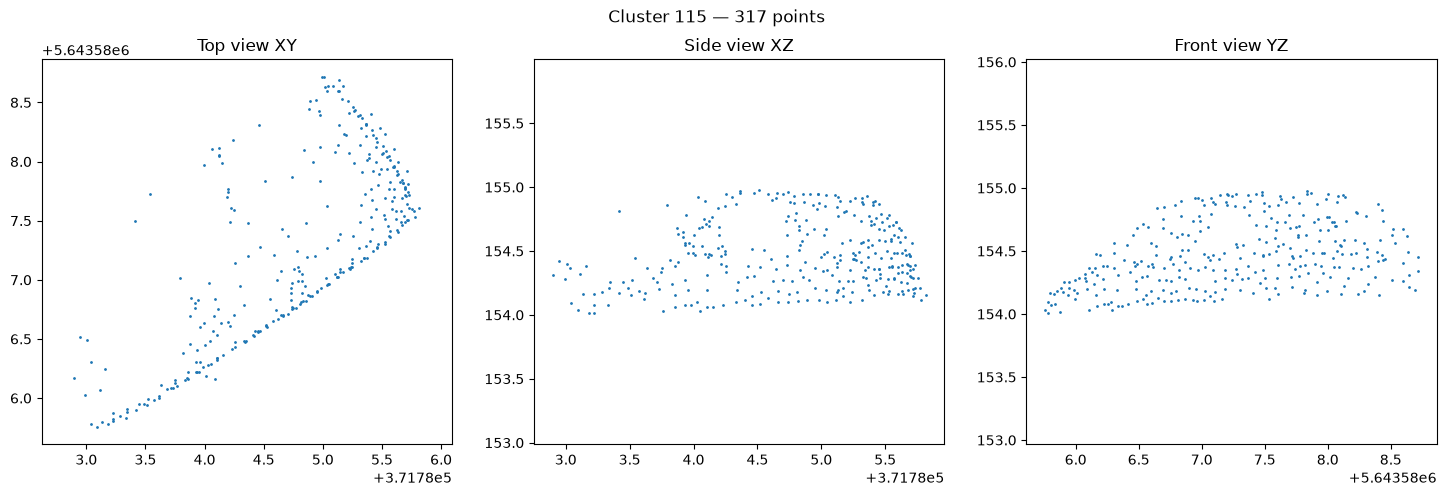

File: 30
Cluster ID: 2
Actual    : tree
Predicted : building
Mobility  : Non-movable
Cluster ID: 2
Number of points: 11910


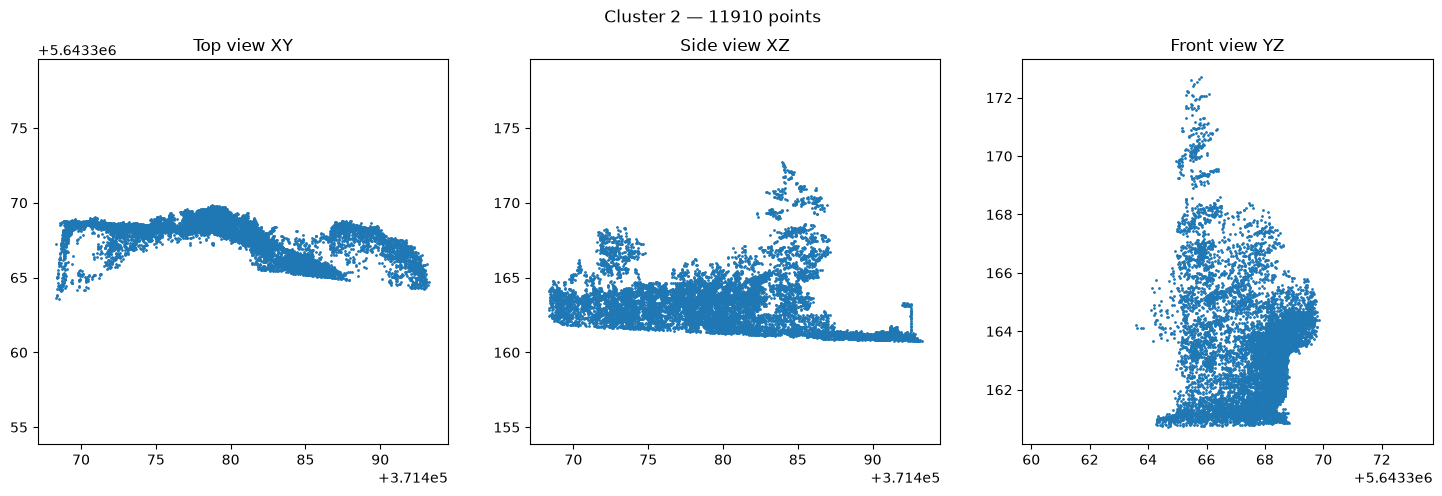

File: 20
Cluster ID: 37
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 37
Number of points: 1124


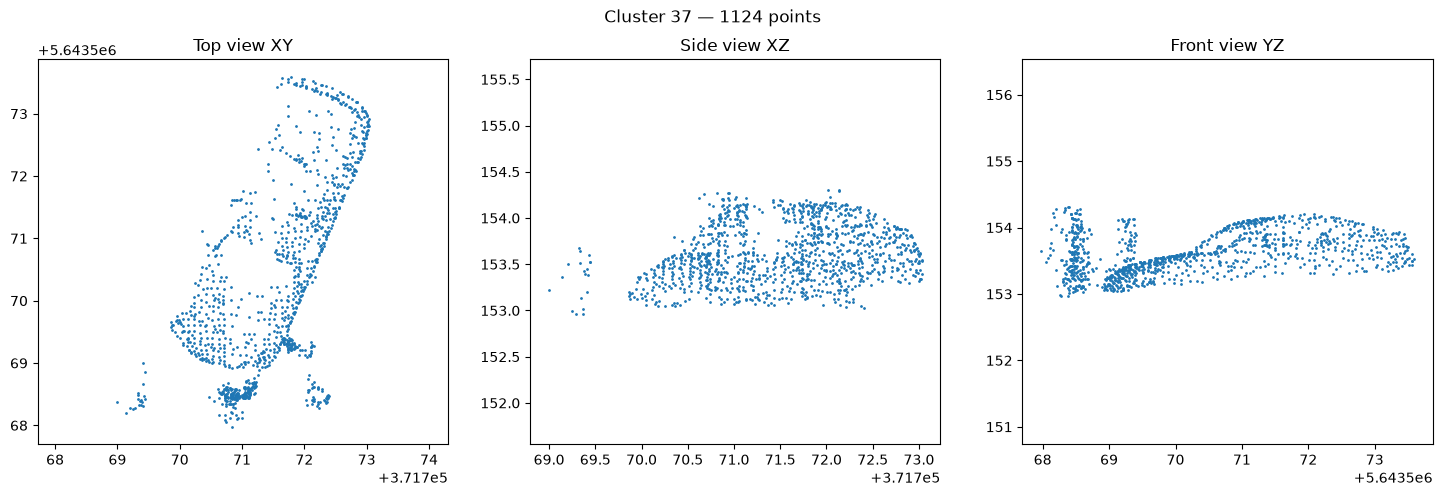

File: 20
Cluster ID: 58
Actual    : pole
Predicted : vehicle
Mobility  : Movable
Cluster ID: 58
Number of points: 1100


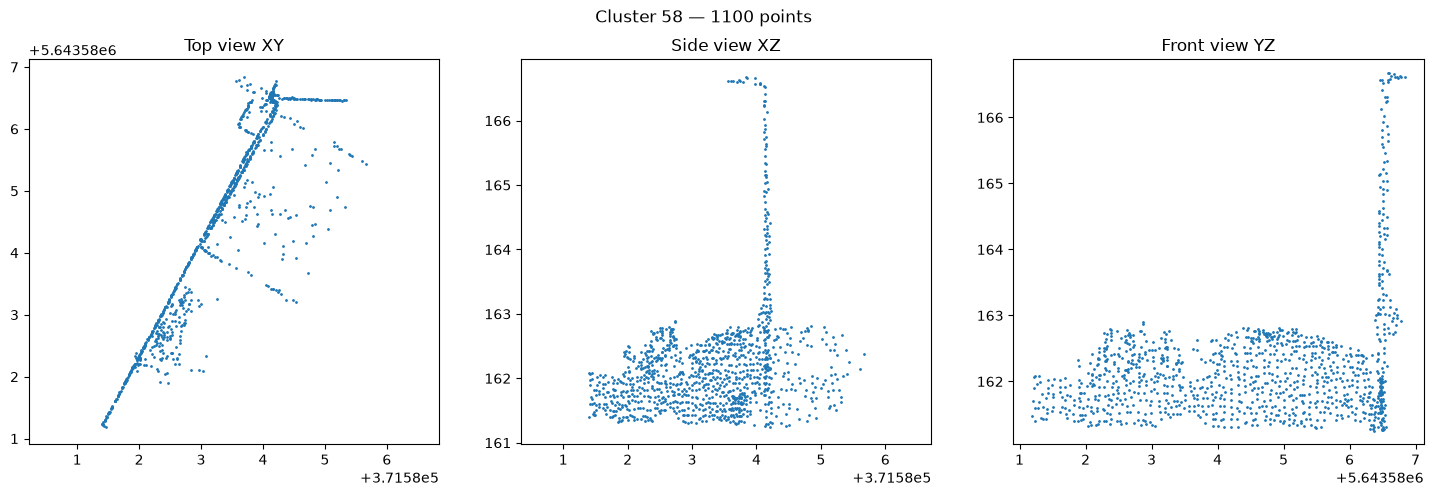

File: 30
Cluster ID: 97
Actual    : building
Predicted : vehicle
Mobility  : Movable
Cluster ID: 97
Number of points: 290


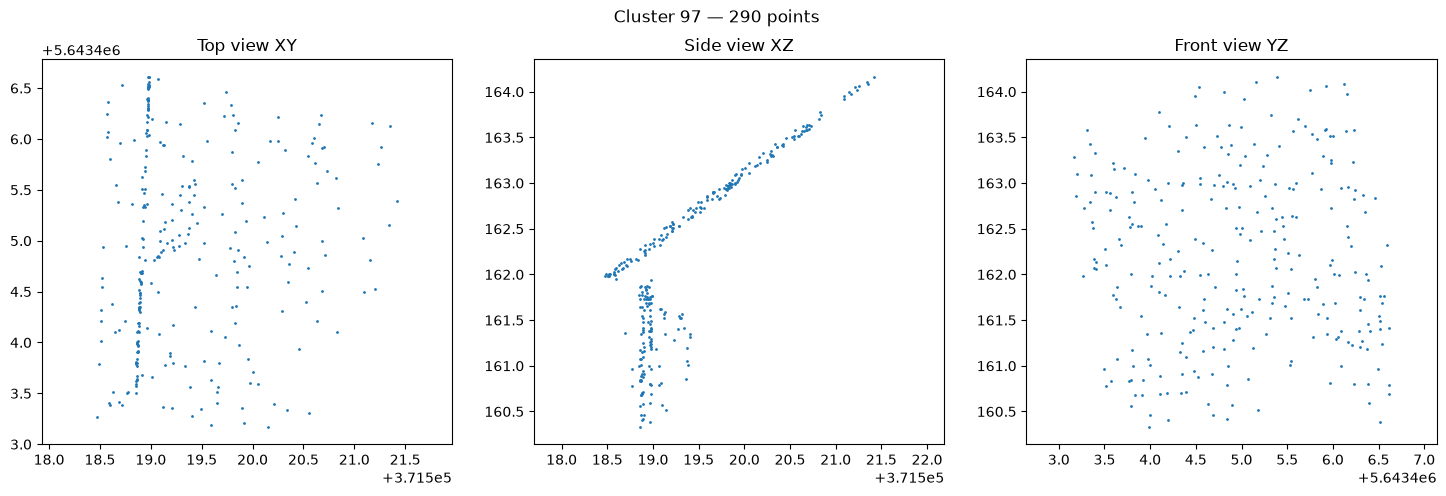

File: 30
Cluster ID: 1
Actual    : wall
Predicted : building
Mobility  : Non-movable
Cluster ID: 1
Number of points: 18187


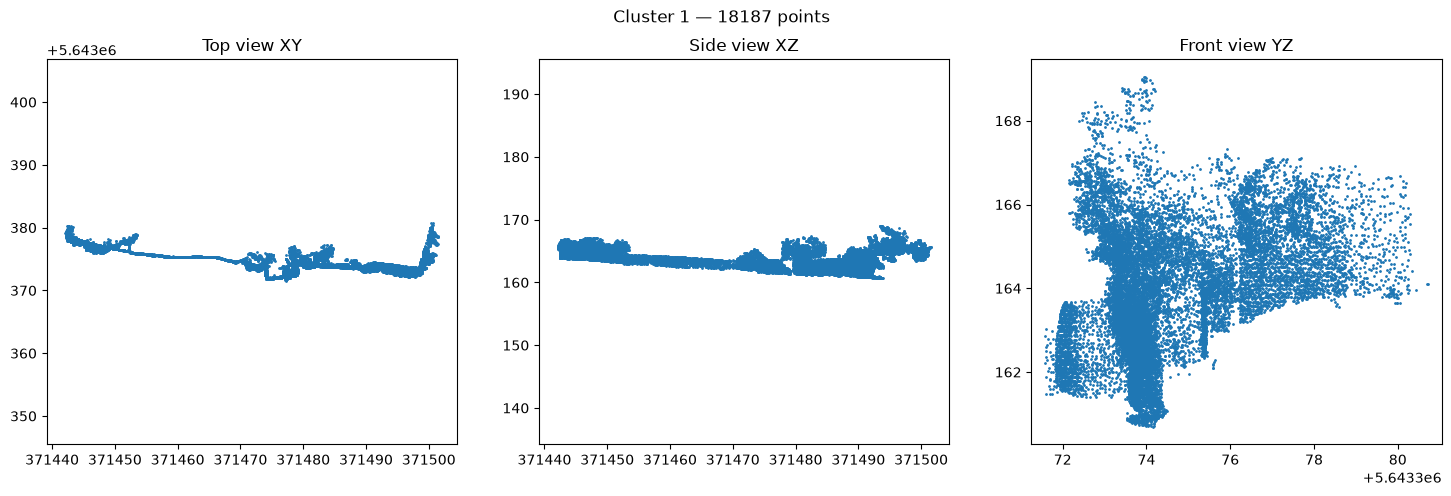

File: 20
Cluster ID: 90
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 90
Number of points: 418


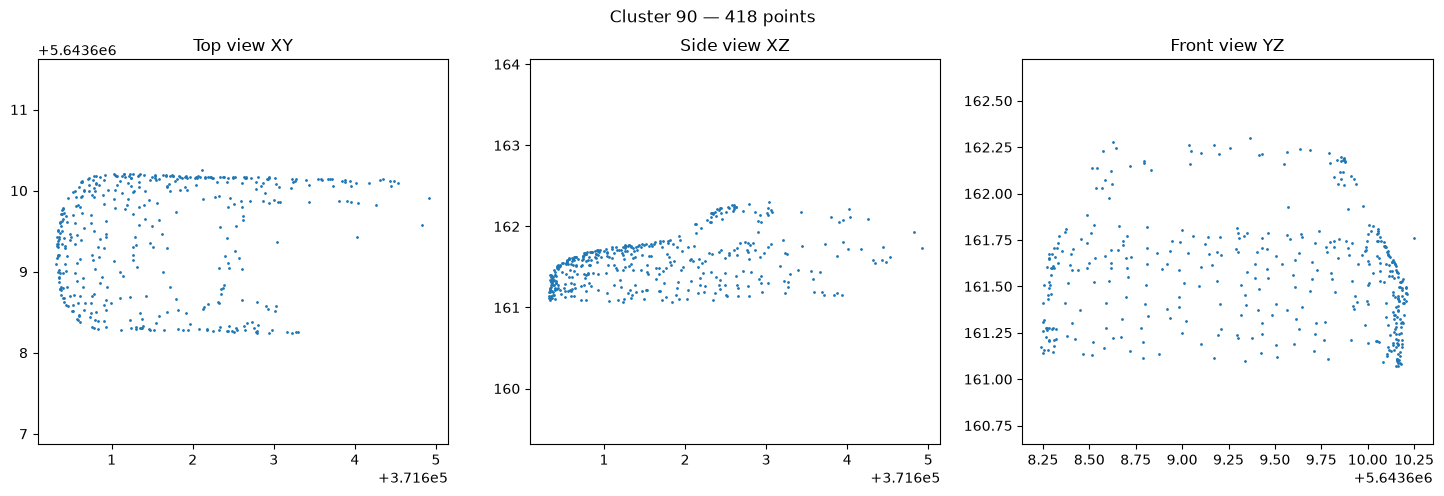

File: 30
Cluster ID: 6
Actual    : building
Predicted : building
Mobility  : Non-movable
Cluster ID: 6
Number of points: 1969


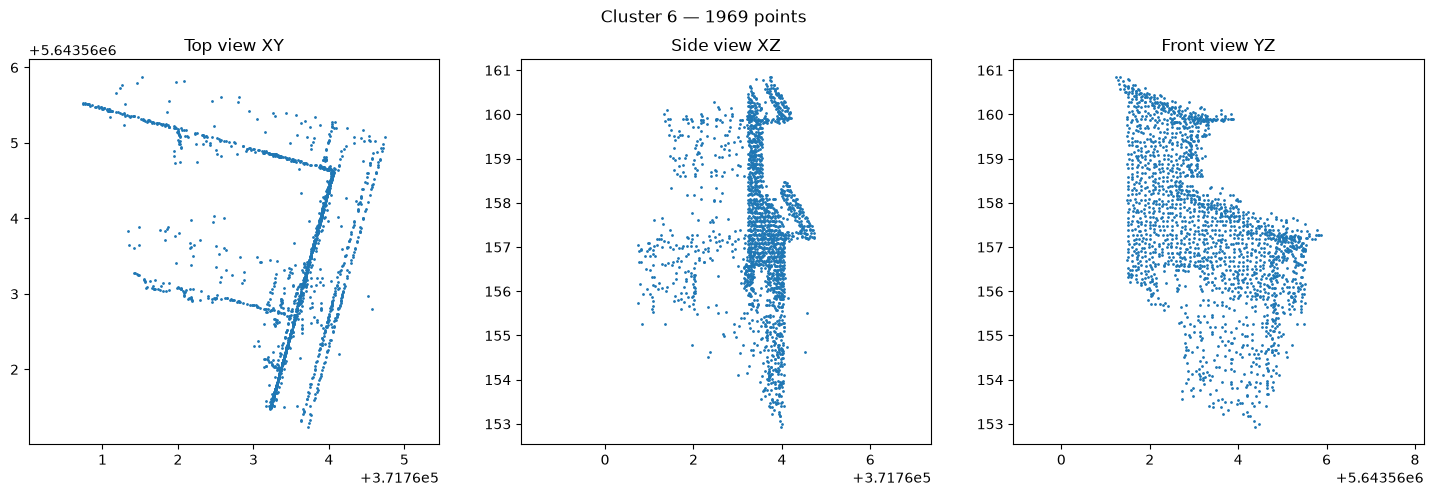

File: 30
Cluster ID: 77
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 77
Number of points: 498


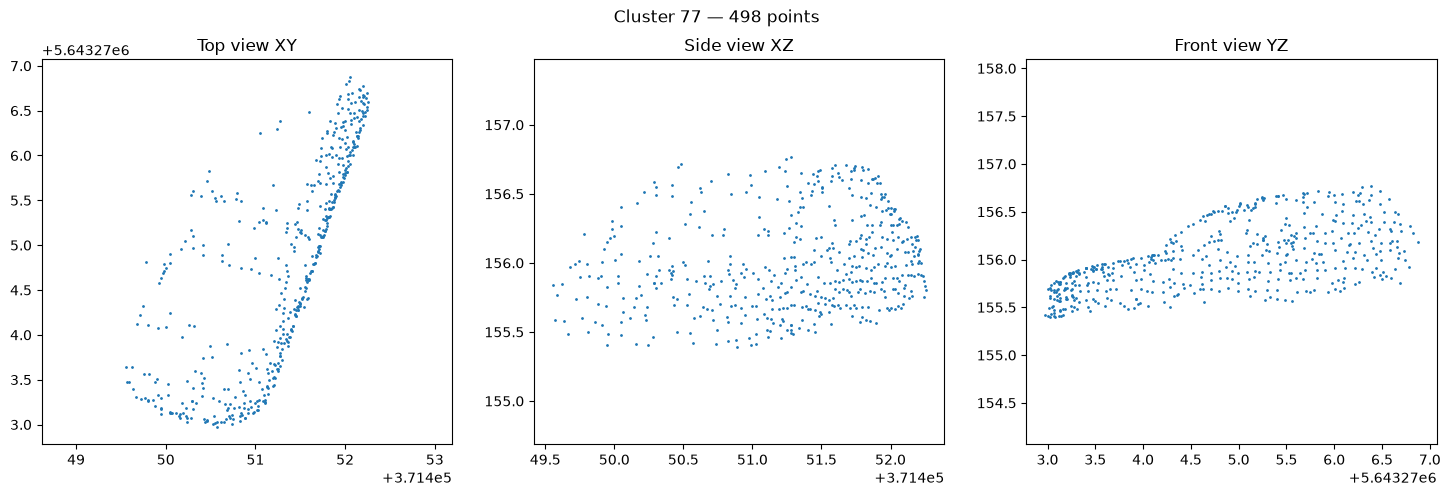

File: 30
Cluster ID: 9
Actual    : wall
Predicted : wall
Mobility  : Non-movable
Cluster ID: 9
Number of points: 19734


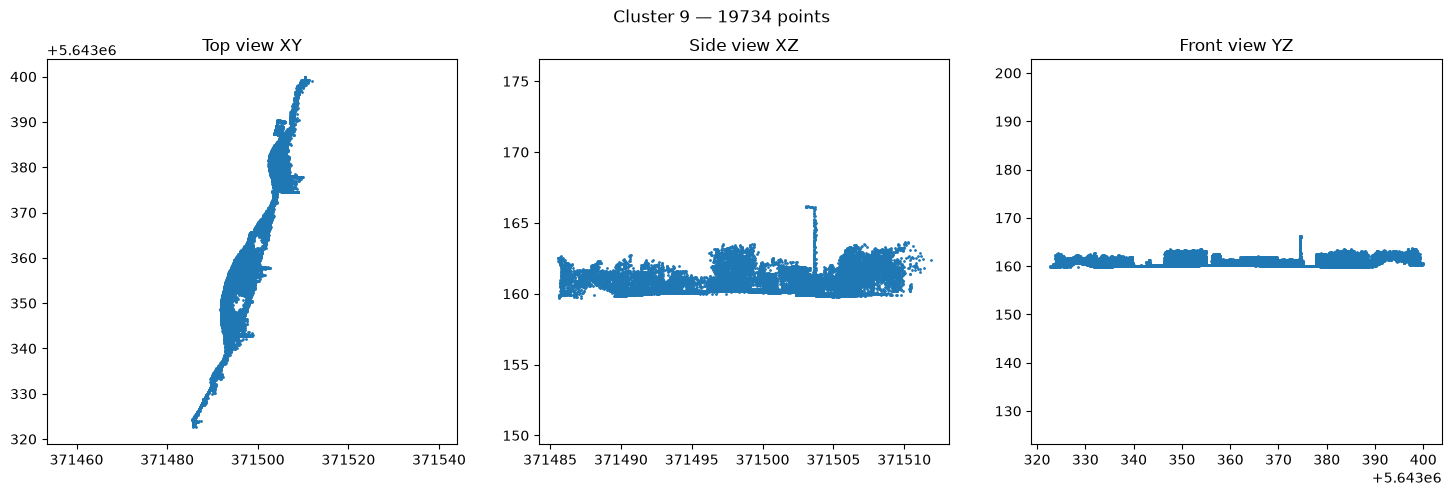

In [41]:
# Display actual and predicted classes for each sample and classify movable/non-movable based on class using Random Forest

show_predictions(
    X_test.index,
    y_test,
    y_pred_rf,
    reverse_label_map,
    point_clouds
)

File: 30
Cluster ID: 63
Actual    : tree
Predicted : tree
Mobility  : Non-movable
Cluster ID: 63
Number of points: 3091


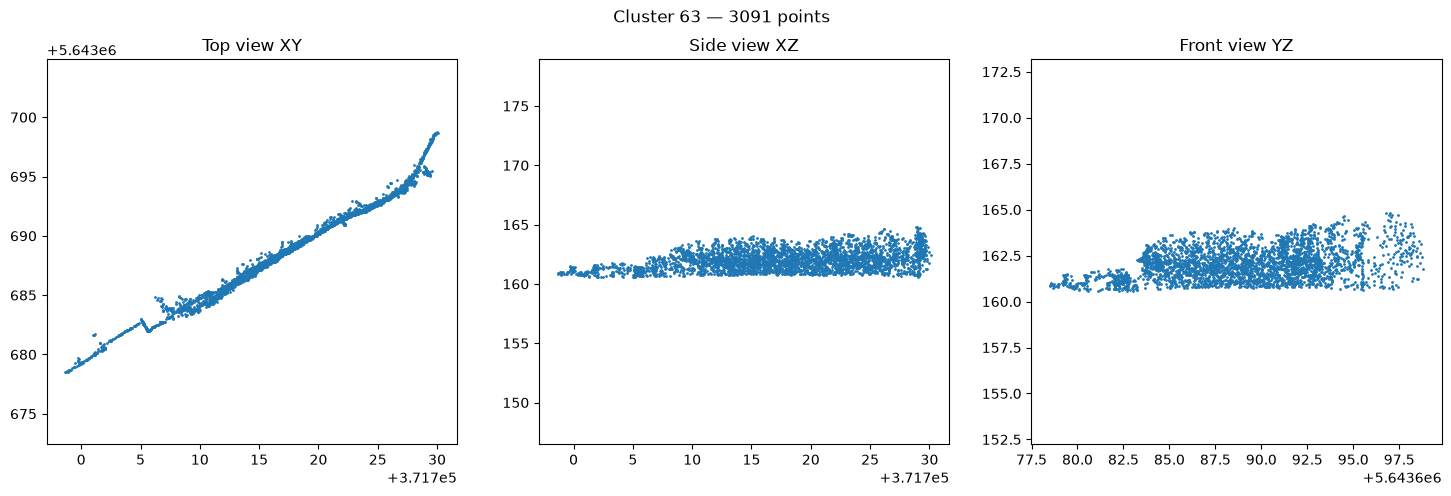

File: 20
Cluster ID: 56
Actual    : building
Predicted : wall
Mobility  : Non-movable
Cluster ID: 56
Number of points: 1411


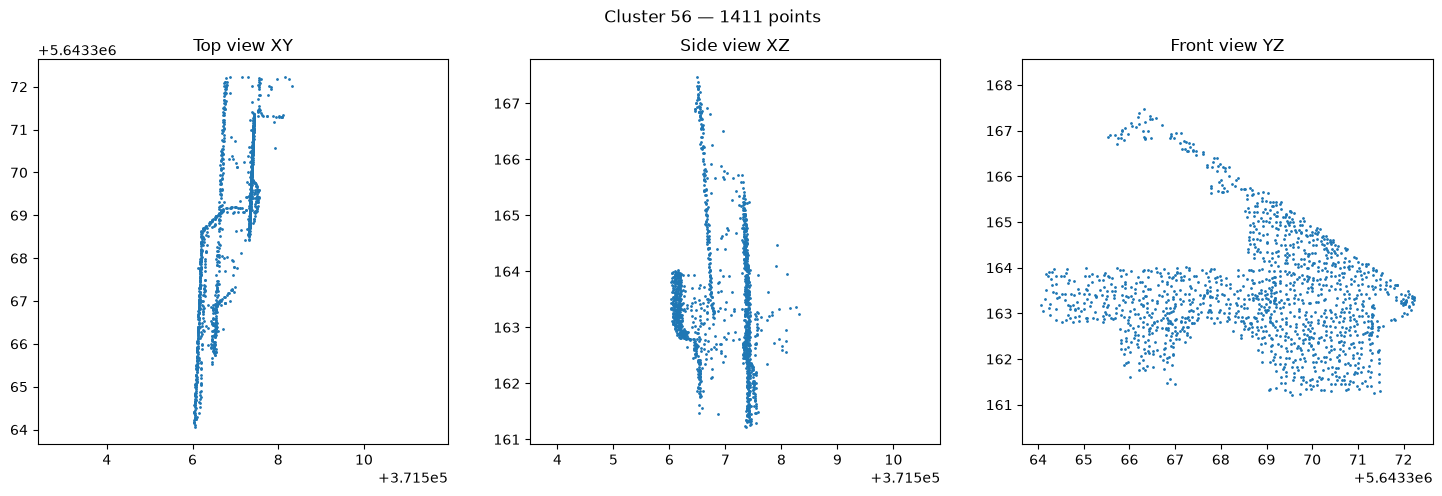

File: 30
Cluster ID: 108
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 108
Number of points: 354


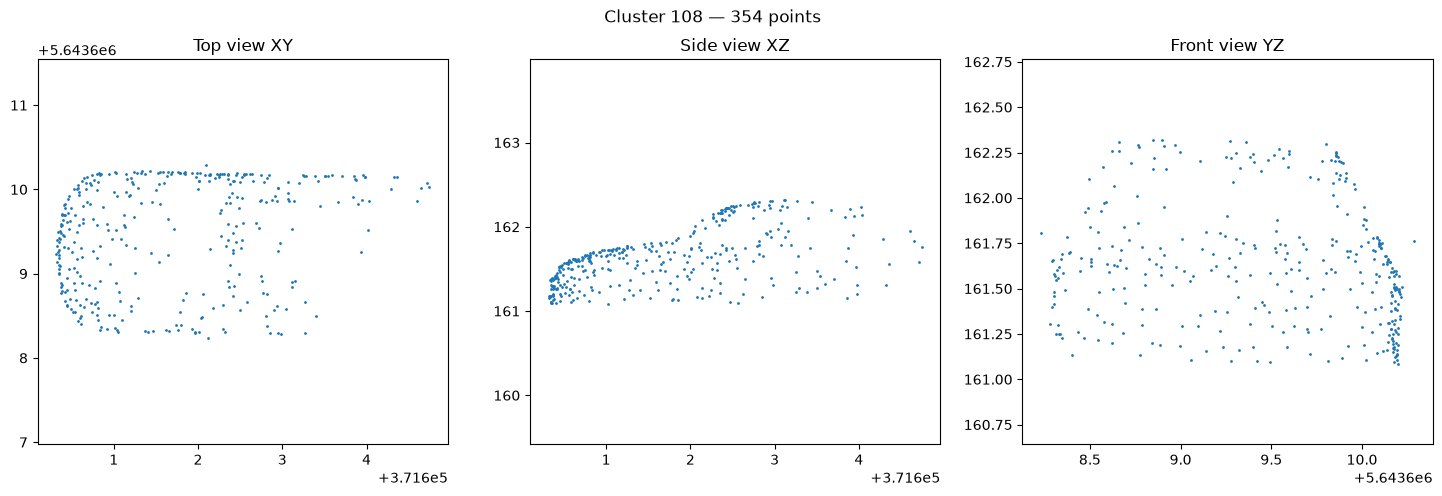

File: 30
Cluster ID: 61
Actual    : vehicle
Predicted : building
Mobility  : Non-movable
Cluster ID: 61
Number of points: 780


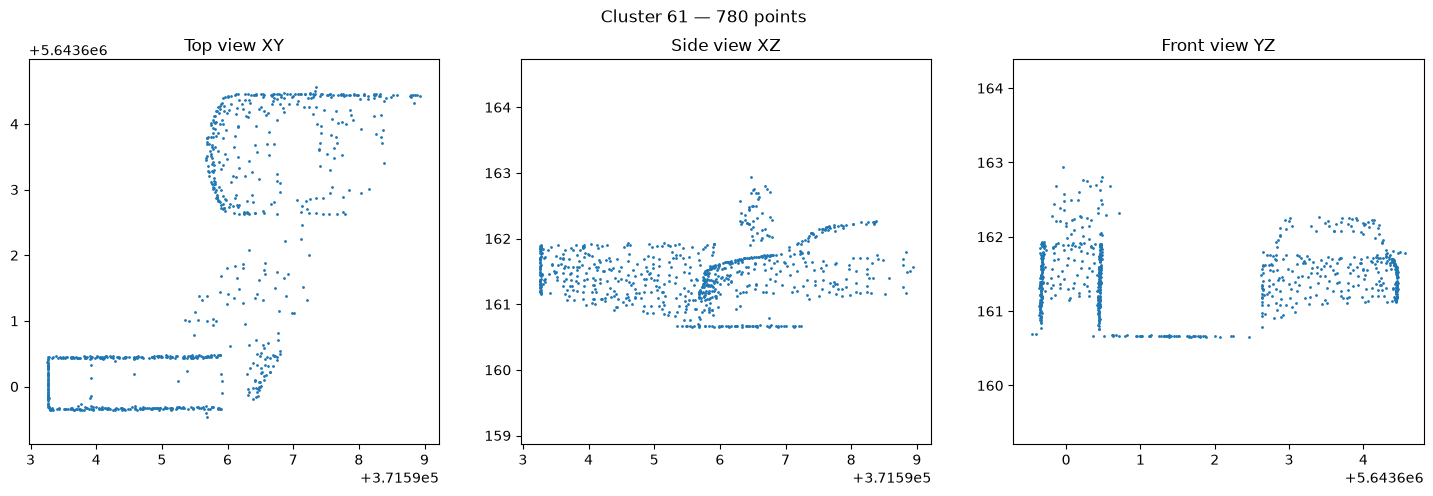

File: 30
Cluster ID: 30
Actual    : wall
Predicted : building
Mobility  : Non-movable
Cluster ID: 30
Number of points: 6072


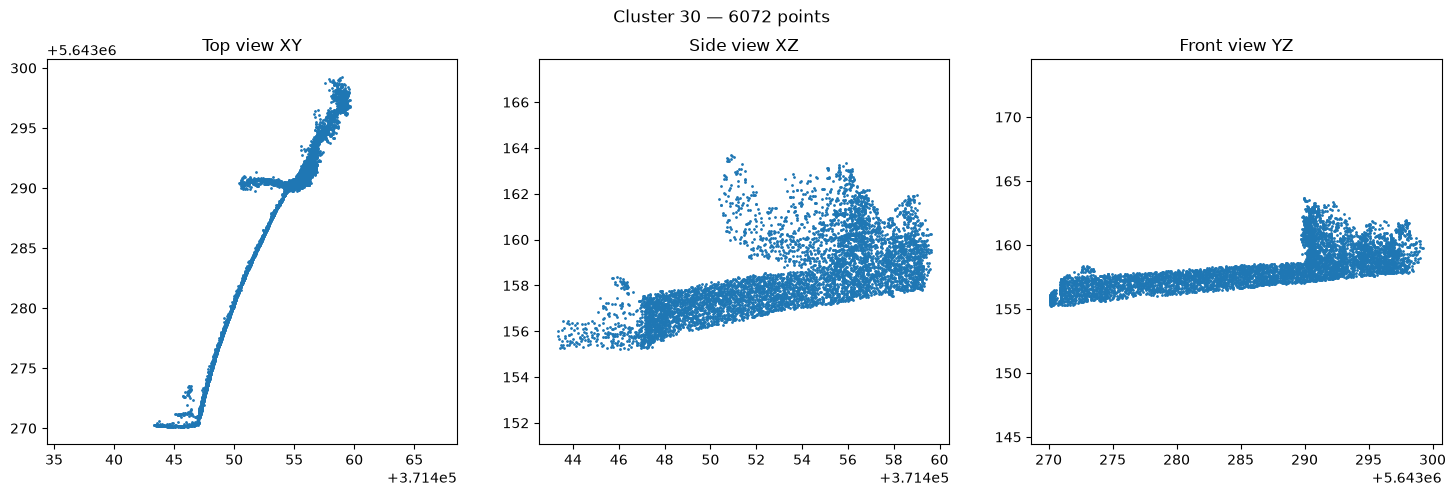

File: 30
Cluster ID: 22
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 22
Number of points: 380


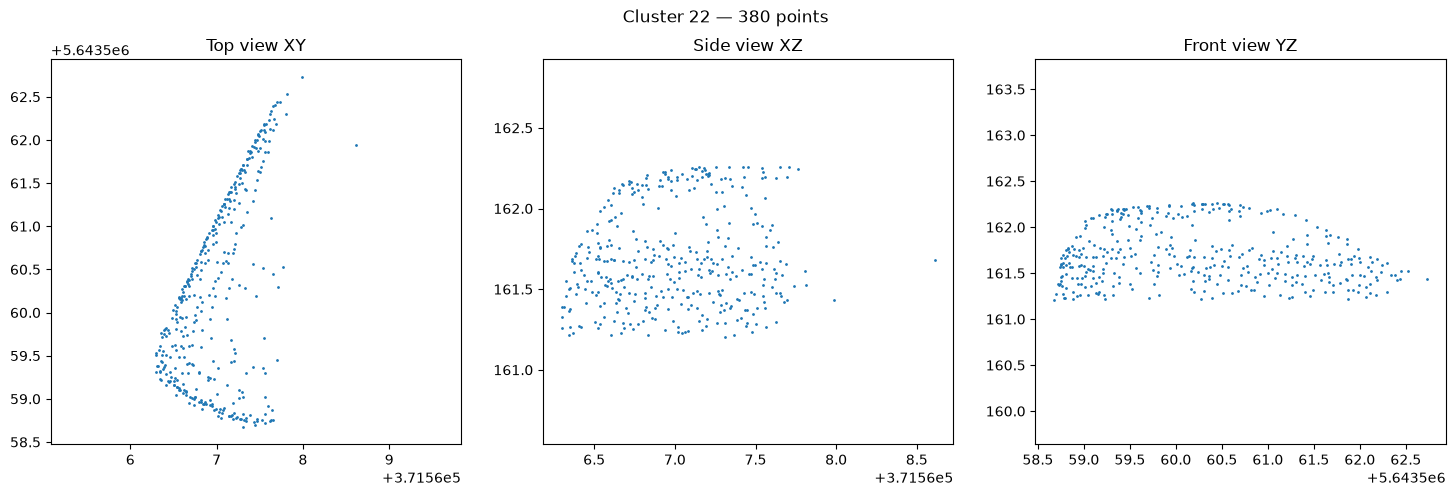

File: 20
Cluster ID: 74
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 74
Number of points: 244


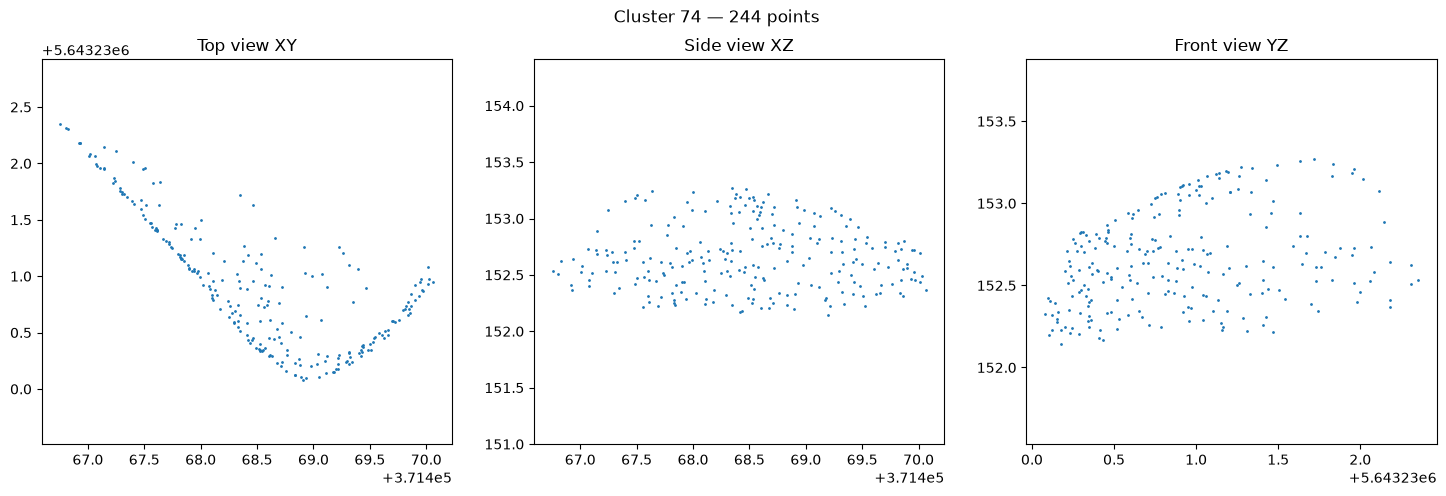

File: 40
Cluster ID: 5
Actual    : wall
Predicted : wall
Mobility  : Non-movable
Cluster ID: 5
Number of points: 6987


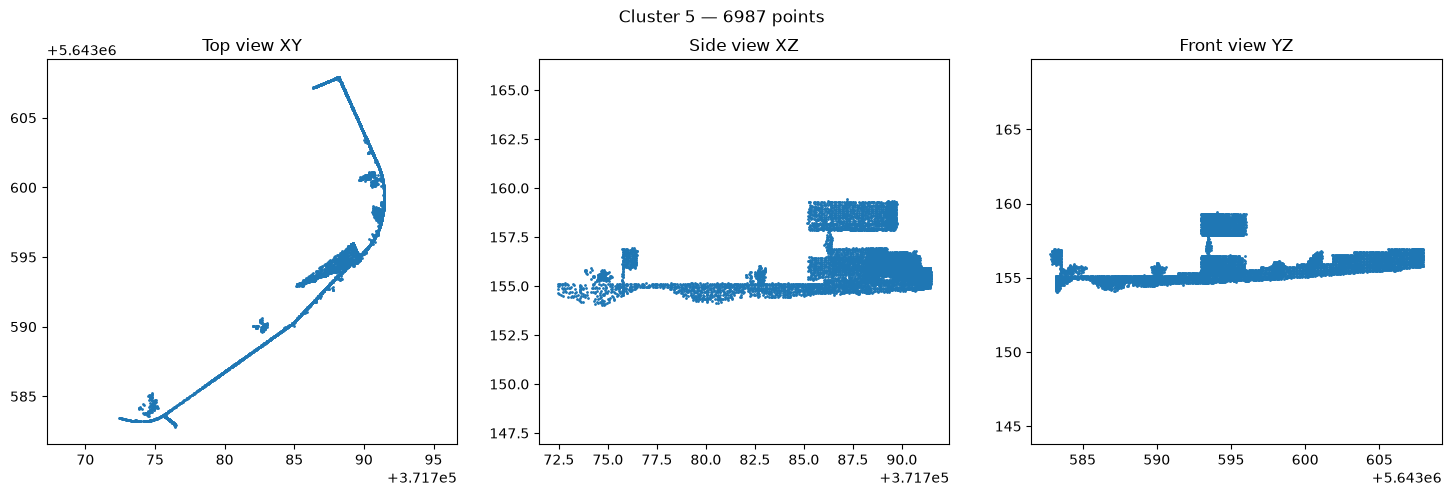

File: 30
Cluster ID: 115
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 115
Number of points: 317


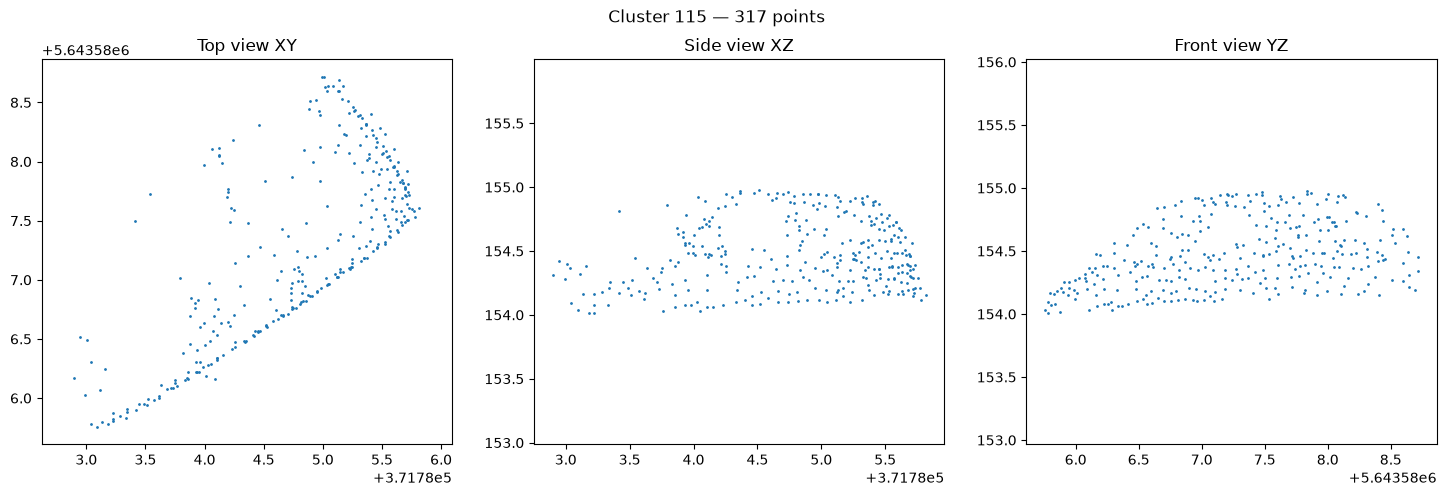

File: 30
Cluster ID: 2
Actual    : tree
Predicted : building
Mobility  : Non-movable
Cluster ID: 2
Number of points: 11910


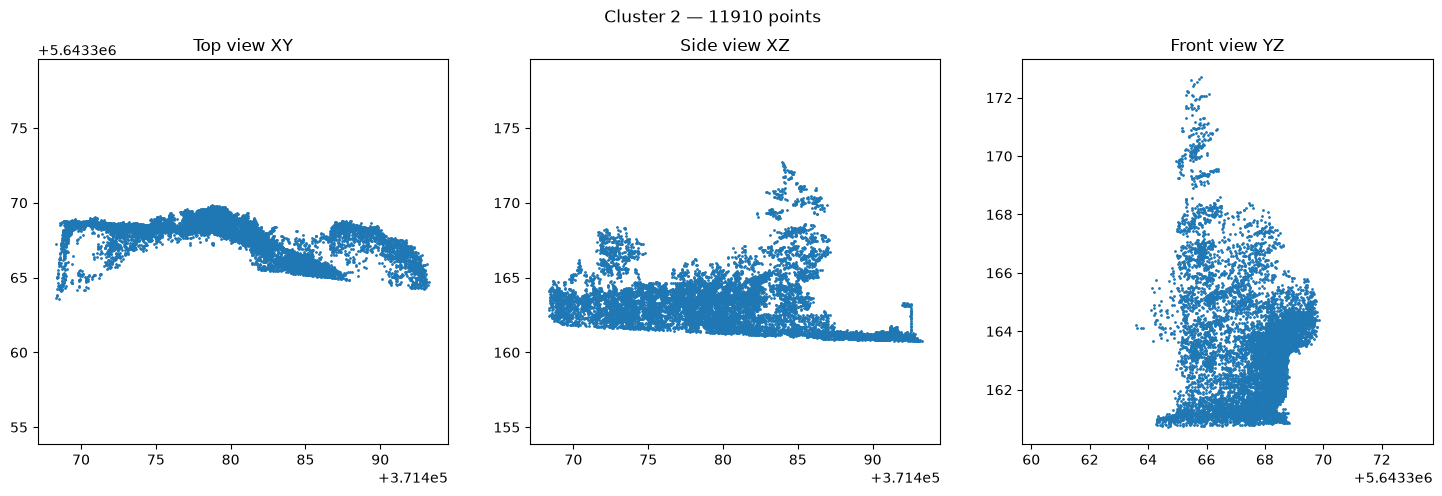

File: 20
Cluster ID: 37
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 37
Number of points: 1124


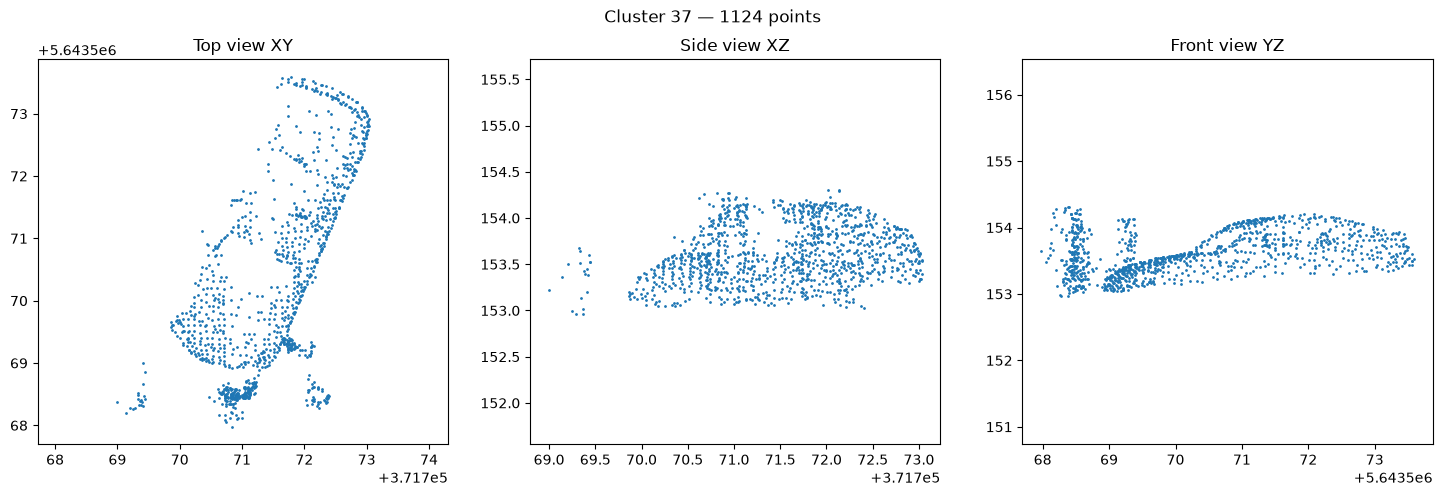

File: 20
Cluster ID: 58
Actual    : pole
Predicted : building
Mobility  : Non-movable
Cluster ID: 58
Number of points: 1100


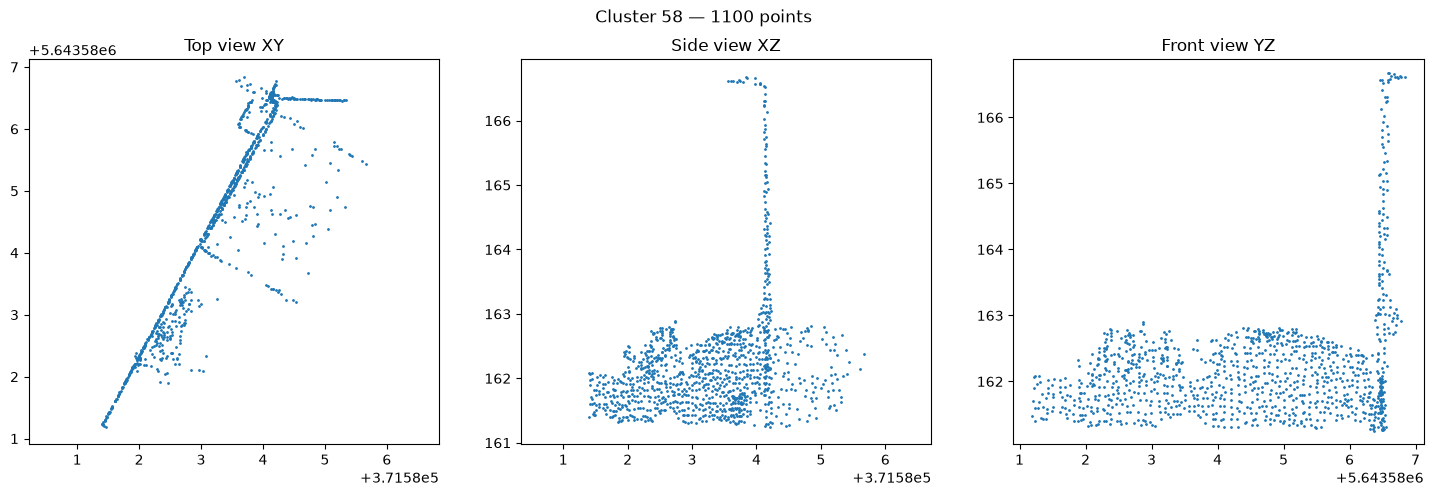

File: 30
Cluster ID: 97
Actual    : building
Predicted : wall
Mobility  : Non-movable
Cluster ID: 97
Number of points: 290


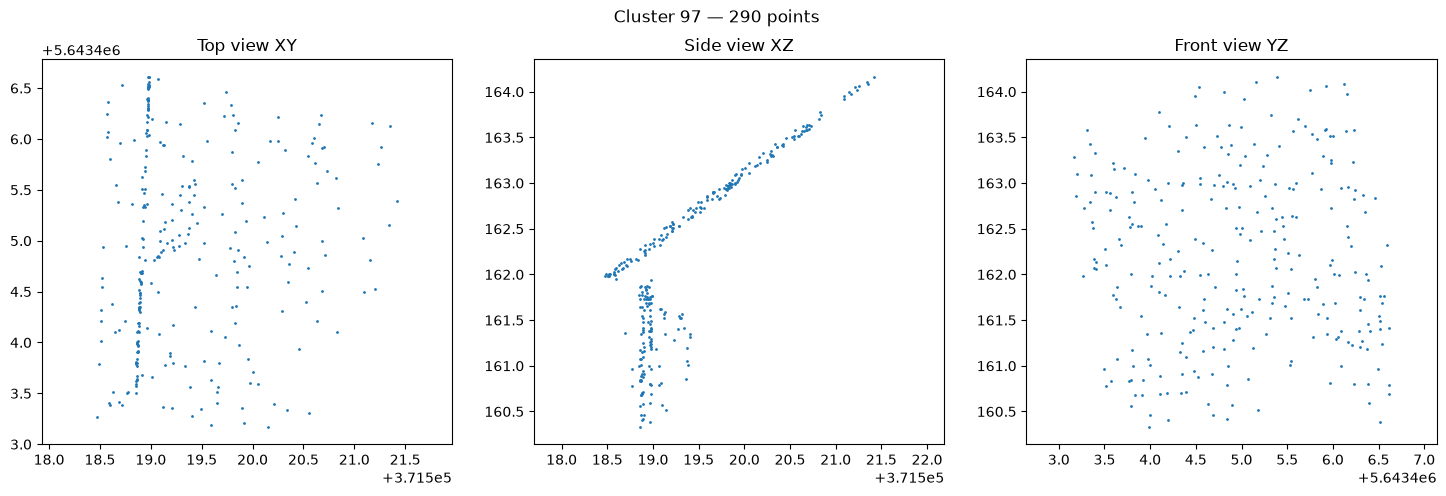

File: 30
Cluster ID: 1
Actual    : wall
Predicted : building
Mobility  : Non-movable
Cluster ID: 1
Number of points: 18187


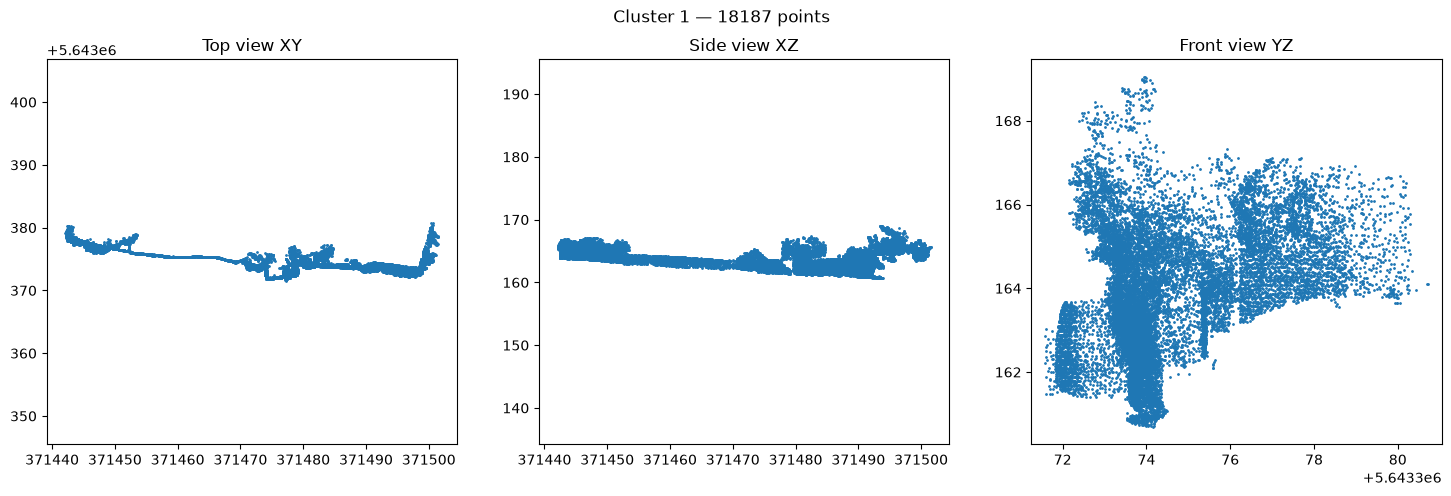

File: 20
Cluster ID: 90
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 90
Number of points: 418


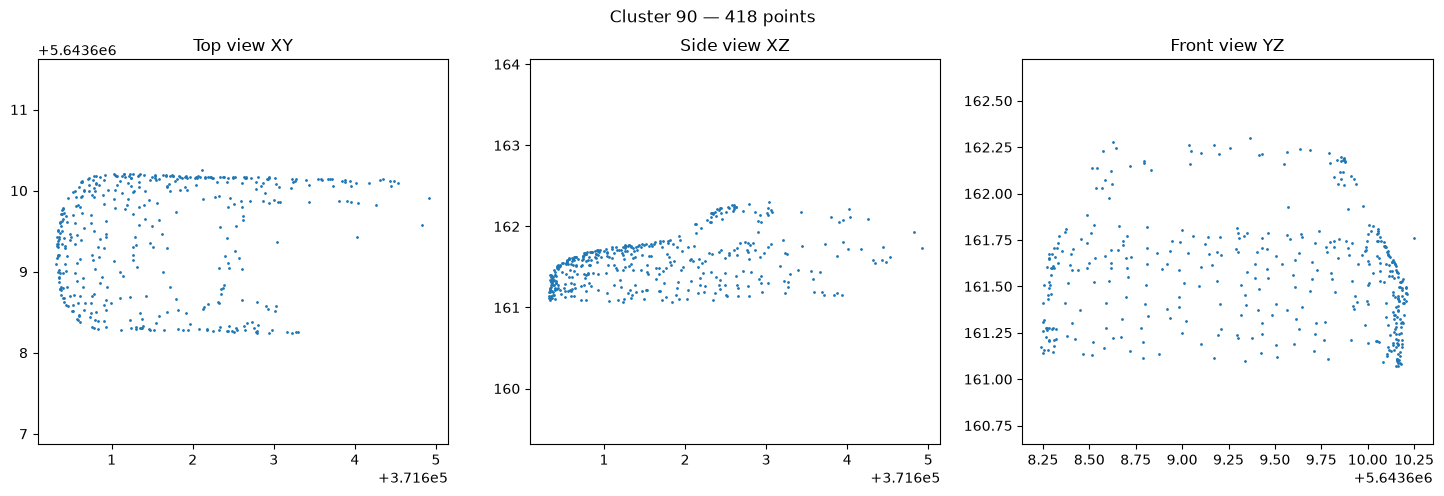

File: 30
Cluster ID: 6
Actual    : building
Predicted : building
Mobility  : Non-movable
Cluster ID: 6
Number of points: 1969


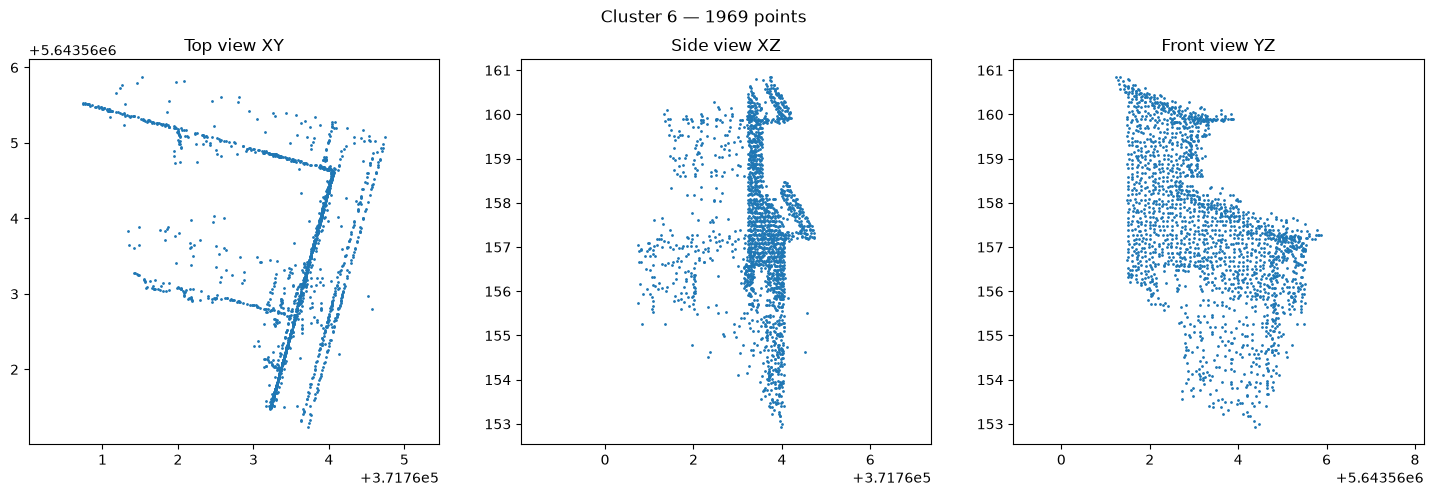

File: 30
Cluster ID: 77
Actual    : vehicle
Predicted : vehicle
Mobility  : Movable
Cluster ID: 77
Number of points: 498


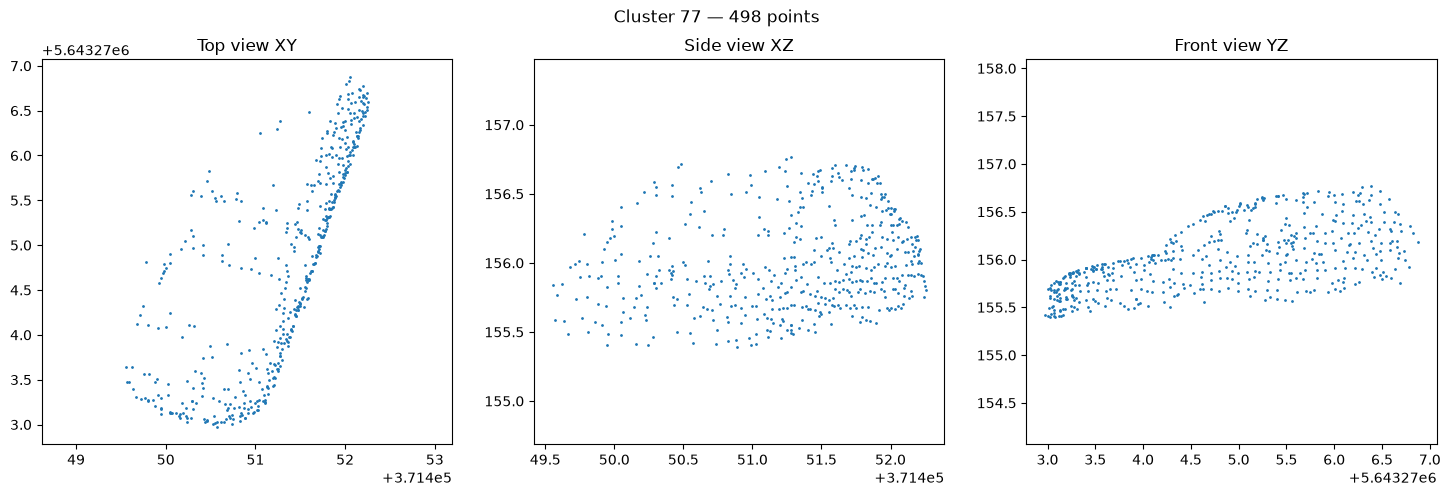

File: 30
Cluster ID: 9
Actual    : wall
Predicted : wall
Mobility  : Non-movable
Cluster ID: 9
Number of points: 19734


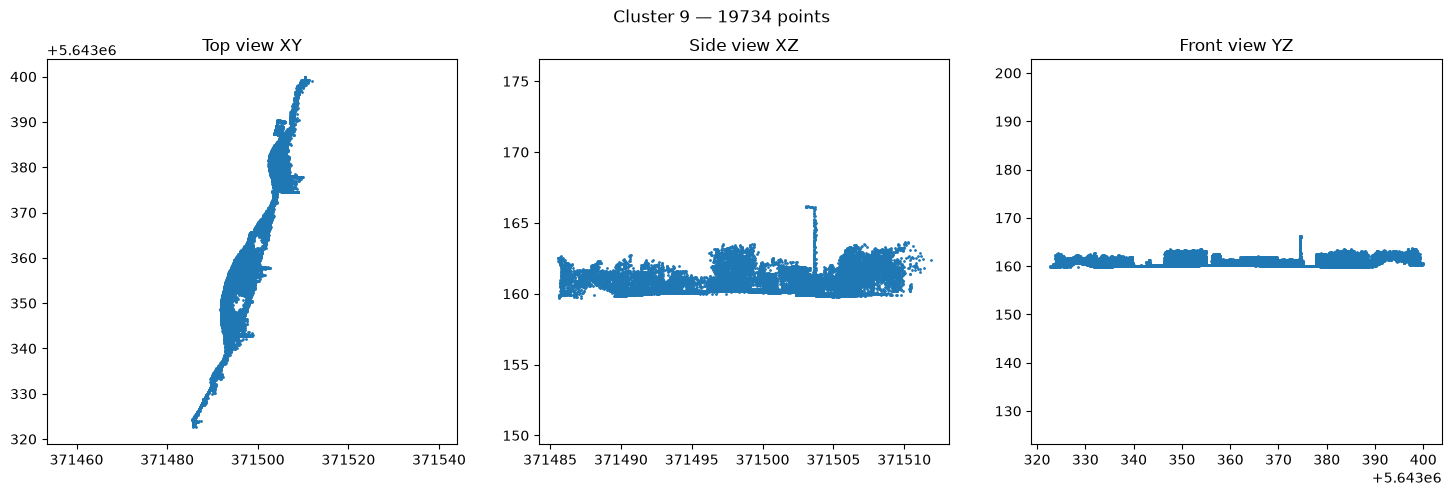

In [43]:
# Display actual and predicted classes for each sample and classify movable/non-movable based on class using XB Boost

show_predictions(
    X_test.index,
    y_test,
    y_pred_xgb,
    reverse_label_map,
    point_clouds
)